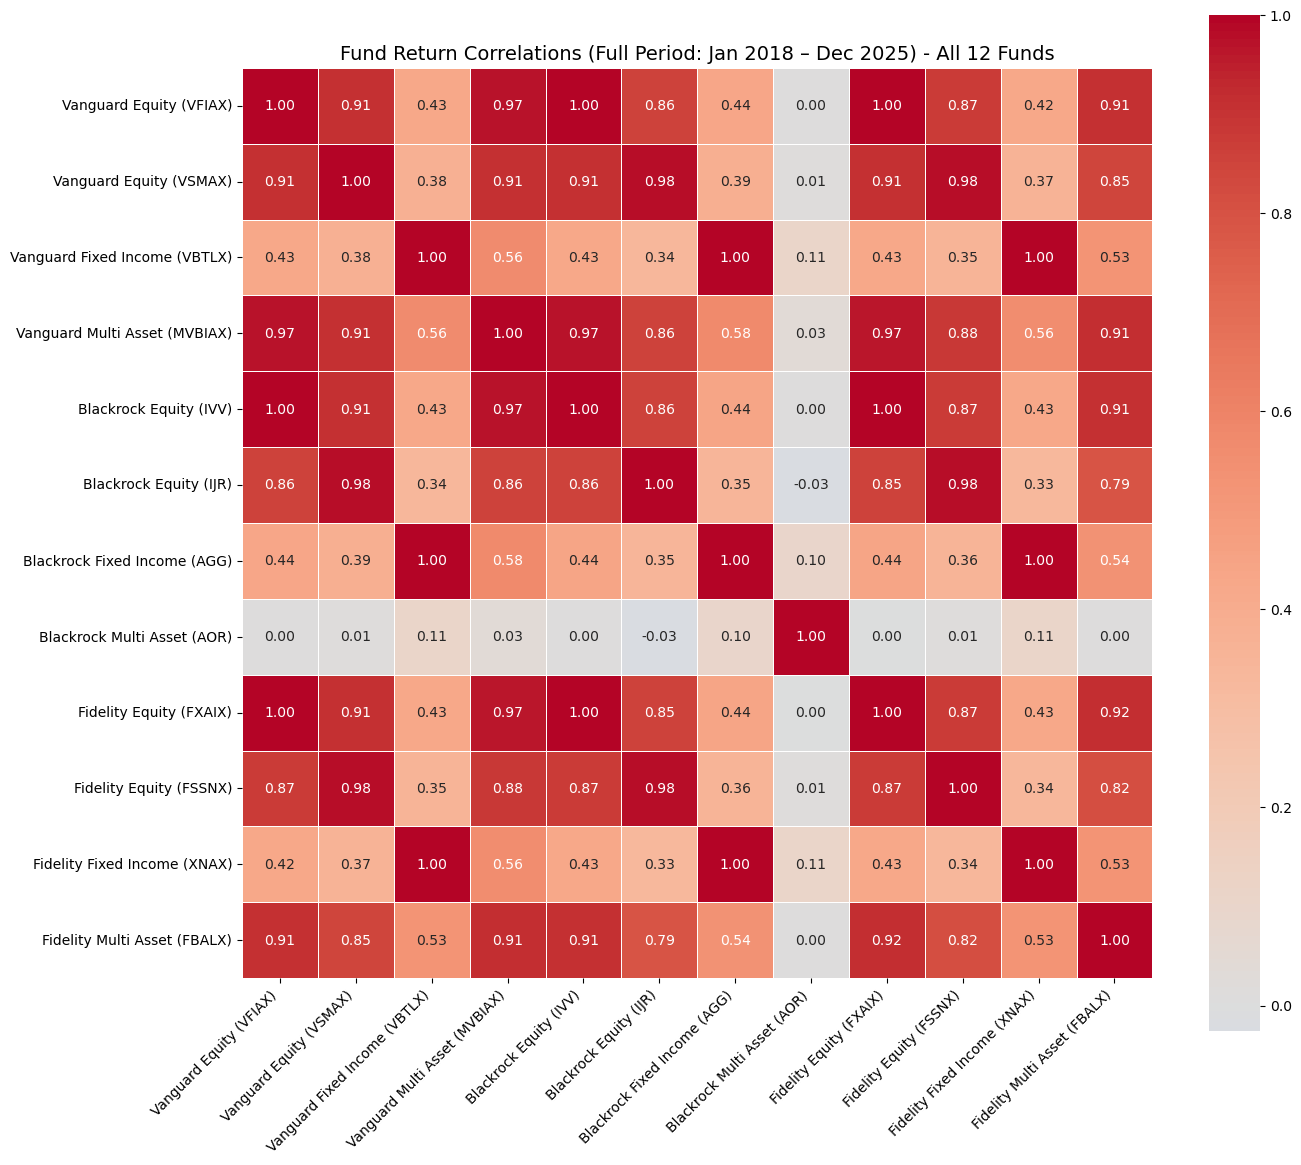

In [2]:
#Correlation Of Returns

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

file_path = '../Excel/mutual_fund_analysis.xlsx'
df = pd.read_excel(file_path, sheet_name='Returns')
df.head()
df.set_index(df.columns[0], inplace=True)
corr_matrix = df.corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, 
            annot=True, 
            fmt='.2f', 
            cmap= 'coolwarm', 
            center=0, 
            square=True, 
            linewidths=0.5)

plt.title('Fund Return Correlations (Full Period: Jan 2018 – Dec 2025) - All 12 Funds', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

===== Optimal Portfolio (Max Sharpe) =====
Expected Annual Return : 9.76%
Annual Volatility      : 14.25%
Sharpe Ratio           : 0.475


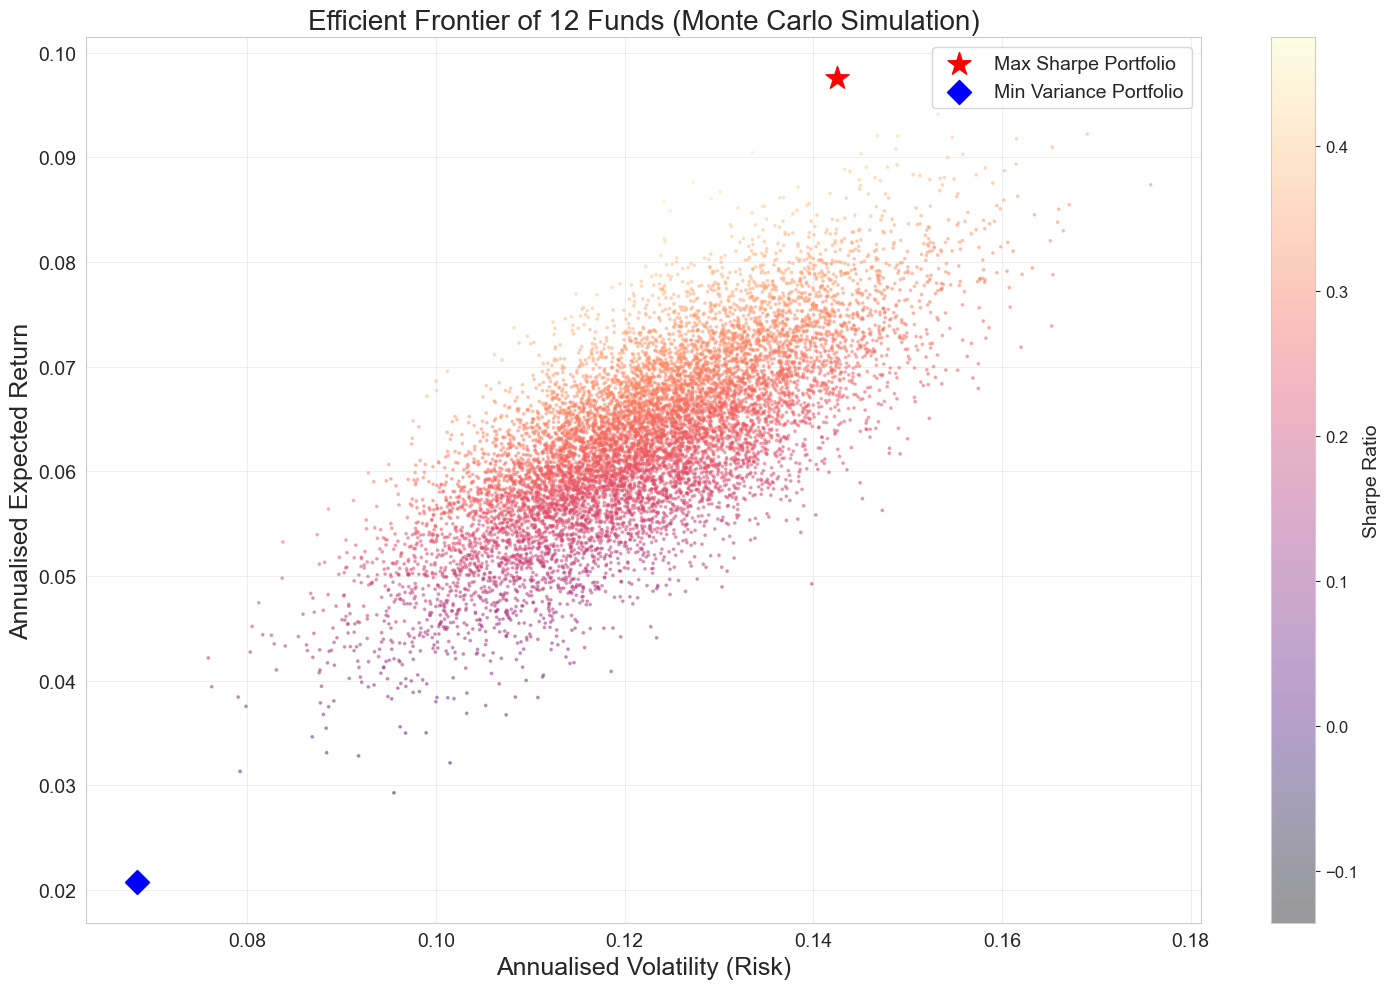

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assume results[0] = returns, results[1] = volatilities, results[2] = Sharpe ratios
# Also have opt_return, opt_std, opt_sharpe, min_var_return, min_var_std, risk_free_rate

# -------------------------------
# 1. Bin portfolios by risk and find the frontier
# -------------------------------
vols = results[1]
rets = results[0]

# Create bins for volatility (e.g., 100 bins)
n_bins = 100
vol_bins = np.linspace(vols.min(), vols.max(), n_bins)
frontier_vol = []
frontier_ret = []

for i in range(len(vol_bins)-1):
    mask = (vols >= vol_bins[i]) & (vols < vol_bins[i+1])
    if np.any(mask):
        max_ret = rets[mask].max()
        # Use the midpoint of the bin as volatility for plotting
        frontier_vol.append((vol_bins[i] + vol_bins[i+1])/2)
        frontier_ret.append(max_ret)

# Convert to numpy arrays for plotting
frontier_vol = np.array(frontier_vol)
frontier_ret = np.array(frontier_ret)

# Sort by volatility
sort_idx = np.argsort(frontier_vol)
frontier_vol = frontier_vol[sort_idx]
frontier_ret = frontier_ret[sort_idx]

# -------------------------------
# 2. Plot the efficient frontier curve (C‑shaped)
# -------------------------------
sns.set_style('whitegrid')
plt.figure(figsize=(14, 8))

# Plot all simulated portfolios (optional, but keep it light)
plt.scatter(vols, rets, c=results[2], cmap='plasma', 
            marker='o', s=3, alpha=0.3, label='Simulated portfolios')

# Plot the efficient frontier line (C‑shape)
plt.plot(frontier_vol, frontier_ret, 'b-', linewidth=2.5, 
         label='Efficient frontier (upper envelope)')

# Mark the minimum variance portfolio
plt.scatter(min_var_std, min_var_return, marker='D', 
            color='blue', s=150, edgecolors='black', 
            label=f'Min Variance Portfolio\nReturn: {min_var_return:.2%}\nVol: {min_var_std:.2%}')

# Mark the max Sharpe (tangency) portfolio
plt.scatter(opt_std, opt_return, marker='*', 
            color='red', s=300, edgecolors='black', 
            label=f'Tangency (Max Sharpe) Portfolio\nReturn: {opt_return:.2%}\nVol: {opt_std:.2%}\nSharpe: {opt_sharpe:.2f}')

# Capital Market Line
x_cml = np.linspace(0, max(vols)*1.05, 50)
y_cml = risk_free_rate + opt_sharpe * x_cml
plt.plot(x_cml, y_cml, 'k--', linewidth=1.5, 
         label=f'Capital Market Line (Sharpe = {opt_sharpe:.2f})')

# Formatting
plt.xlabel('Annualised Volatility (Risk)', fontsize=14)
plt.ylabel('Annualised Expected Return', fontsize=14)
plt.title('Efficient Frontier (C‑shape) of 12 Funds', fontsize=16)
plt.legend(loc='best', fontsize=10)
plt.grid(True, alpha=0.3)
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap='plasma'), 
                    ax=plt.gca(), label='Sharpe Ratio')
cbar.ax.yaxis.label.set_size(12)

plt.tight_layout()
plt.savefig('efficient_frontier_Cshape.png', dpi=300, bbox_inches='tight')
plt.savefig('efficient_frontier_Cshape.pdf', bbox_inches='tight')
plt.show()